# DX603 Final Project Milestone: Explore the Data Sets and Model Families

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**

### What We Will Do in This Milestone

This milestone is the first stage of your final machine learning project. You will have **three weeks** to explore real-world data, prepare it for modeling, and investigate several approaches to prediction. We will follow a simplified version of the machine learning workflow developed throughout the course:

1. **Explore the data:** Investigate two datasets, identify important characteristics and challenges, and select one for your project.
2. **Prepare the data:** Clean the selected dataset, handle missing values and categorical features, and create training, validation, and test sets without data leakage.
3. **Establish a baseline:** Train and evaluate a linear or logistic regression model as a starting point.
4. **Experiment with features:** Conduct two distinct feature-engineering experiments to investigate how changes in the predictors affect performance.
5. **Compare model families:** Compare a linear or logistic model, a tree ensemble, and a feedforward neural network, and investigate how one change in model complexity affects performance.

The goal is not necessarily to obtain the best possible prediction at this stage, but to **develop a sound experimental workflow and understand how different modeling choices affect performance**.

In the final stage of the project, you will have another three weeks to build on this work with additional experiments, improve and select your models using validation results, evaluate your final model on the test set, and submit both a completed code notebook and a written report.

### The Datasets

You will explore two datasets and then choose **one** to use for the remainder of your project.

| Dataset | Prediction task | Target | Primary validation metric |
|---|---|---|---|
| **Zillow** | Regression: predict assessed property value | `taxvaluedollarcnt` | **MAE** (lower is better) |
| **Hotel Booking Demand** | Binary classification: predict booking cancellation | `is_canceled` (1 = canceled) | **F1** for predicting canceled bookings (higher is better) |

**Zillow:** This is a subset of the housing dataset used in the 2017 Zillow Prize competition on Kaggle. Your goal is to predict the assessed tax value of a property from a large collection of property descriptors. The data contains missing values, potentially redundant or irrelevant features, and outliers that make accurate prediction challenging.

**Hotel Booking Demand:** This dataset contains information about hotel reservations, including booking characteristics, guest information, and reservation details. Your goal is to predict whether a reservation will be canceled. In addition to the usual challenges of preparing real-world data, you will need to consider classification metrics and whether features would actually be available when making a prediction.

Neither dataset is preferred, and you will not be graded on which one you choose. **After Problem 1, use the same dataset for Problems 2–5 and for your final project.**

### How to Complete This Notebook

- Run the provided setup cells first. Complete the computational tasks using Python code, adding working code cells as needed.
- Write your reflections in the designated **Python answer variables**, using triple-quoted strings, as in the weekly homeworks. Use the exact variable names specified.
- **Do not modify the Graded Answer cells**, and be sure to run them before submitting.
- Base your conclusions on **your own computed results**. Keep relevant code, plots, outputs, and reflections visible in your submitted notebook.
- Use `random_state=42` where possible, document your modeling choices, and do not delete the provided task instructions.
- **Do not evaluate your models on the test set in this milestone.** You will reserve that evaluation for the final submission.

**Total: 100 points.**

In [1]:

# General utilities
import os
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Data splitting
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
    PolynomialFeatures
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Models
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# TensorFlow / Keras setup
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


I0000 00:00:1794776381.578298    2694 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794776410.032603    2694 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.22.0-rc0
Available GPUs: []


E0000 00:00:1794776412.525509    2694 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## Setup and Dataset Loading

In Problem 1, you will explore two datasets before choosing one for the remainder of your project.

Run the setup cell below to load both datasets. If a dataset is already available locally, the code will use that copy. Otherwise, it will automatically download the dataset and save it for future use.

The original datasets will remain unchanged during Problem 1.

**Dataset Sources**

- **Zillow:** Course-provided housing dataset.
- **Hotel Booking Demand:** António, Almeida, and Nunes (2019). [Dataset on Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand).

In [2]:

# Download a dataset only if it is not already available locally

def load_dataset(url):
    filename = os.path.basename(urlparse(url).path)

    if not os.path.exists(filename):
        try:
            print(f"Downloading {filename}...")
            response = requests.get(url, timeout=120)
            response.raise_for_status()
            with open(filename, "wb") as f:
                f.write(response.content)
            print("File downloaded successfully.")
        except requests.exceptions.RequestException as e:
            raise RuntimeError(
                f"Error downloading {filename}: {e}"
            ) from e
    else:
        print(f"{filename} already exists. Skipping download.")

    return pd.read_csv(filename)


# Zillow dataset
zillow_url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/zillow_dataset.csv"
df_zillow = load_dataset(zillow_url)

# Hotel Booking Demand dataset
hotel_url = (
    "https://raw.githubusercontent.com/aaqibqadeer/"
    "Hotel-booking-demand/master/hotel_bookings.csv"
)
df_hotel = load_dataset(hotel_url)

print("\nDataset dimensions:")
print("Zillow:", df_zillow.shape)
print("Hotel Booking:", df_hotel.shape)


zillow_dataset.csv already exists. Skipping download.
hotel_bookings.csv already exists. Skipping download.

Dataset dimensions:
Zillow: (77613, 55)
Hotel Booking: (119390, 32)


## Problem 1 — Explore, Select, and Define a Prediction Task [15 points]

### Part A: Preliminary EDA of Both Datasets [10 points]

Before selecting a dataset for your project, conduct a brief exploratory analysis of **both** datasets, using the original dataframes `df_zillow` and `df_hotel`.

For each dataset:

**a. Dataset dimensions and types:** Report the number of observations, the number of predictors (excluding the target), and the number of columns currently stored as numerical and categorical. Remember that a column's data type does not necessarily reflect its meaning; for example, identifiers may be stored as integers.

**b. Target distribution:** Visualize the distribution of the target variable. For Zillow, include appropriate summary statistics for assessed property values. For Hotel Booking, report cancellation counts and percentages.

**c. Missing values:** Identify the five columns with the highest percentages of missing values (or all columns with missing values if fewer than five).

**d. Feature types:** Identify any high-cardinality categorical features or numeric-looking codes and identifiers that may require special handling during preprocessing.

**e. Data quality:** Describe one or two additional potential data-quality concerns you observe, explaining briefly why they might matter for modeling.

Keep this investigation focused. You do not need to plot every feature or perform any cleaning at this stage. The goal is to **understand the characteristics and challenges of each dataset before choosing one for your project.**

In [3]:
# Your code here; add as many cells as you wish
df_zillow
df_hotel

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,01-07-15
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,01-07-15
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,02-07-15
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,02-07-15
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,03-07-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,06-09-17
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,07-09-17
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,07-09-17
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,07-09-17


In [4]:
# Zillow information

zillow_predictors = df_zillow.drop(
    columns=["taxvaluedollarcnt"]
)

zillow_numeric = zillow_predictors.select_dtypes(
    include="number"
)

zillow_categorical = zillow_predictors.select_dtypes(
    exclude="number"
)

print("Zillow observations:", len(df_zillow))
print("Zillow predictors:", zillow_predictors.shape[1])
print("Zillow numerical columns:", zillow_numeric.shape[1])
print("Zillow categorical columns:", zillow_categorical.shape[1])


# Hotel Booking information

hotel_predictors = df_hotel.drop(
    columns=["is_canceled"]
)

hotel_numeric = hotel_predictors.select_dtypes(
    include="number"
)

hotel_categorical = hotel_predictors.select_dtypes(
    exclude="number"
)

print("\nHotel observations:", len(df_hotel))
print("Hotel predictors:", hotel_predictors.shape[1])
print("Hotel numerical columns:", hotel_numeric.shape[1])
print("Hotel categorical columns:", hotel_categorical.shape[1])

Zillow observations: 77613
Zillow predictors: 54
Zillow numerical columns: 49
Zillow categorical columns: 5

Hotel observations: 119390
Hotel predictors: 31
Hotel numerical columns: 19
Hotel categorical columns: 12


count    7.757800e+04
mean     4.901506e+05
std      6.537979e+05
min      1.000000e+03
25%      2.068985e+05
50%      3.588785e+05
75%      5.690000e+05
max      4.906124e+07
Name: taxvaluedollarcnt, dtype: float64


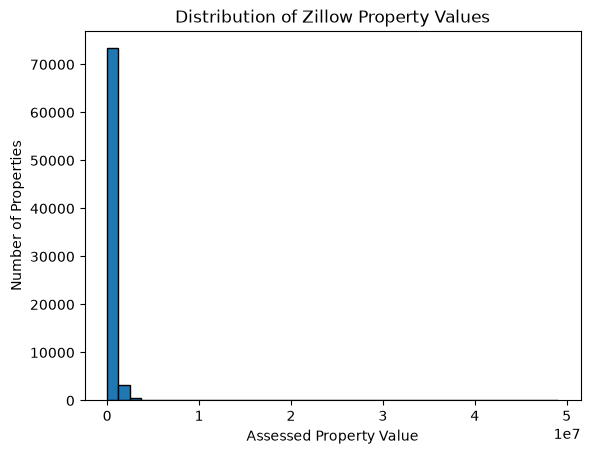

In [5]:
zillow_values = df_zillow["taxvaluedollarcnt"]

print(zillow_values.describe())

plt.hist(
    zillow_values.dropna(),
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Zillow Property Values")
plt.xlabel("Assessed Property Value")
plt.ylabel("Number of Properties")

plt.show()

Cancellation counts:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation percentages:
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64


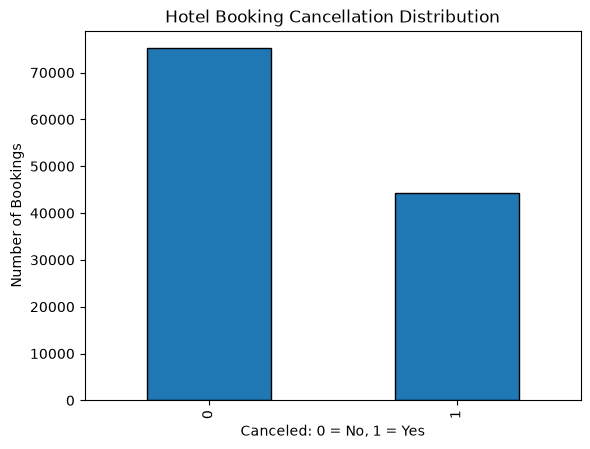

In [6]:
cancellation_counts = (
    df_hotel["is_canceled"].value_counts()
)

cancellation_percentages = (
    df_hotel["is_canceled"].value_counts(
        normalize=True
    ) * 100
)

print("Cancellation counts:")
print(cancellation_counts)

print("\nCancellation percentages:")
print(cancellation_percentages)

cancellation_counts.sort_index().plot.bar(
    edgecolor="black"
)

plt.title("Hotel Booking Cancellation Distribution")
plt.xlabel("Canceled: 0 = No, 1 = Yes")
plt.ylabel("Number of Bookings")

plt.show()

In [7]:
zillow_missing = (
    df_zillow.isna().mean() * 100
).sort_values(ascending=False)

hotel_missing = (
    df_hotel.isna().mean() * 100
).sort_values(ascending=False)

print("Top five Zillow columns with missing values:")
print(zillow_missing.head())

print("\nTop five Hotel columns with missing values:")
print(hotel_missing.head())

Top five Zillow columns with missing values:
buildingclasstypeid     99.980673
finishedsquarefeet13    99.945885
basementsqft            99.935578
storytypeid             99.935578
yardbuildingsqft26      99.909809
dtype: float64

Top five Hotel columns with missing values:
company               94.306893
agent                 13.686238
country                0.408744
children               0.003350
arrival_date_month     0.000000
dtype: float64


In [8]:
print("Zillow categorical columns:")

for column in zillow_categorical.columns:
    print(
        column,
        zillow_categorical[column].nunique()
    )

print("\nHotel categorical columns:")

for column in hotel_categorical.columns:
    print(
        column,
        hotel_categorical[column].nunique()
    )

Zillow categorical columns:
hashottuborspa 1
propertycountylandusecode 75
propertyzoningdesc 1907
fireplaceflag 1
taxdelinquencyflag 1

Hotel categorical columns:
hotel 2
arrival_date_month 12
meal 5
country 177
market_segment 8
distribution_channel 5
reserved_room_type 10
assigned_room_type 12
deposit_type 3
customer_type 4
reservation_status 3
reservation_status_date 926


In [9]:
print("Possible Zillow codes or identifiers:")
print([
    "parcelid",
    "fips",
    "regionidcity",
    "regionidcounty",
    "regionidneighborhood",
    "regionidzip"
])

print("\nPossible Hotel codes or identifiers:")
print([
    "agent",
    "company"
])

Possible Zillow codes or identifiers:
['parcelid', 'fips', 'regionidcity', 'regionidcounty', 'regionidneighborhood', 'regionidzip']

Possible Hotel codes or identifiers:
['agent', 'company']


In [10]:
print(
    "Zillow duplicate rows:",
    df_zillow.duplicated().sum()
)

print(
    "Zillow missing targets:",
    df_zillow["taxvaluedollarcnt"].isna().sum()
)

print(
    "Hotel duplicate rows:",
    df_hotel.duplicated().sum()
)

print(
    "Hotel missing targets:",
    df_hotel["is_canceled"].isna().sum()
)

Zillow duplicate rows: 199
Zillow missing targets: 35
Hotel duplicate rows: 31994
Hotel missing targets: 0


In [11]:
total_guests = (
    df_hotel["adults"]
    + df_hotel["children"].fillna(0)
    + df_hotel["babies"]
)

zero_guest_bookings = (
    total_guests == 0
).sum()

total_nights = (
    df_hotel["stays_in_week_nights"]
    + df_hotel["stays_in_weekend_nights"]
)

zero_night_bookings = (
    total_nights == 0
).sum()

negative_adr = (
    df_hotel["adr"] < 0
).sum()

print("Hotel bookings with zero guests:", zero_guest_bookings)
print("Hotel bookings with zero nights:", zero_night_bookings)
print("Hotel bookings with negative ADR:", negative_adr)

Hotel bookings with zero guests: 180
Hotel bookings with zero nights: 715
Hotel bookings with negative ADR: 1


### Reflection 1.A — Preliminary Data Exploration

Compare the two datasets based on your preliminary EDA. 

> What did you learn about their target distributions, missing values, feature types, and potential data-quality problems?

Refer to specific results from your tables and plots. Identify the most important modeling challenges you anticipate for each dataset, and briefly explain why they might affect predictive performance.

Write **a coherent response of approximately 100–200 words** in `a1a`.

In [12]:
# Your answer here, NOT in the next cell

a1a = """
The two datasets show different challenges in their data.
Zillow has 77,613 observations and its property-value target is strongly right-skewed.
The median value is about $358,879, but the maximum is over $49 million, so there a several large valued houses which skew the data and model.
Zillow also has missing data, with its five columns missing almost all of their values.
It includes codes such as parcel ID, FIPS, and region IDs that should not automatically be treated as regular numerical measurements.
Hotel Booking has 119,390 observations, and about 37% of the reservations were canceled.
Its biggest missing data issue is company, which is missing about 94% of its values.
The hotel data contains 31,994 duplicate rows, 180 bookings with no guests, and 715 bookings with no nights.
It also contains reservation-status information that could reveal the outcome and cause data leakage.
"""

In [13]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
The two datasets show different challenges in their data.
Zillow has 77,613 observations and its property-value target is strongly right-skewed.
The median value is about $358,879, but the maximum is over $49 million, so there a several large valued houses which skew the data and model.
Zillow also has missing data, with its five columns missing almost all of their values.
It includes codes such as parcel ID, FIPS, and region IDs that should not automatically be treated as regular numerical measurements.
Hotel Booking has 119,390 observations, and about 37% of the reservations were canceled.
Its biggest missing data issue is company, which is missing about 94% of its values.
The hotel data contains 31,994 duplicate rows, 180 bookings with no guests, and 715 bookings with no nights.
It also contains reservation-status information that could reveal the outcome and cause data leakage.



### Part B: Select One Dataset [5 points]

Choose **Zillow** or **Hotel Booking** as the dataset for your final project.

Base your decision on your preliminary EDA, your interest in the prediction task, and the modeling challenges you identified.

Record your selection in `a1_dataset`, using exactly `"Zillow"` or `"Hotel Booking"`.

**Your choice itself is not graded.** You will use this dataset for the remainder of the milestone and the final project.

In [14]:
# Select your dataset: "Zillow" or "Hotel Booking"

a1_dataset = "Hotel Booking"  # "Zillow" or "Hotel Booking"

In [15]:
# Dataset selection and setup
# DO NOT change this cell

assert a1_dataset in ("Zillow", "Hotel Booking"), \
    "Choose exactly 'Zillow' or 'Hotel Booking'."

if a1_dataset == "Zillow":
    selected_raw = df_zillow.copy()
    target = "taxvaluedollarcnt"
    task = "regression"
else:
    selected_raw = df_hotel.copy()
    target = "is_canceled"
    task = "classification"

print("Selected dataset:", a1_dataset, "(stored in selected_raw)")
print("Prediction task:", task)
print("Target:", target)
print("Dataset shape:", selected_raw.shape)

Selected dataset: Hotel Booking (stored in selected_raw)
Prediction task: classification
Target: is_canceled
Dataset shape: (119390, 32)


### Reflection 1.B — Dataset Selection

Explain why you selected this dataset. What attracts you to its prediction task?

> 1. Identify **two specific modeling challenges** revealed by your preliminary EDA,
> 2. Explain how they might affect your approach, and
> 3. Identify **one interesting challenge** in the dataset you did not choose.

Support your discussion with observations from Problem 1.A.

Write **a coherent response of approximately 100–150 words** in `a1b`.

In [16]:
# Your answer here, NOT in the next cell

a1b = """
I selected the Hotel Booking dataset because predicting cancellations feels like a straight forward classification problem.
A hotel could use these predictions for scheduling, room availability, and forecast revenue.
One challenge is missing information, especially company, which is missing for about 94% of the bookings, and agent, which is missing for about 14%.
Will need to determine if they contain relevant information
Another challenge is preventing leakage because reservation_status and reservation_status_date reveal information that would not be available when the reservation is originally made.
I will plan to remove those features before modeling.
The dataset also has numeric-looking codes that are identifiers rather than true measurements.
Zillow was also interesting, but its extreme property values and several columns with more than 99% missing data would make preprocessing and evaluation more difficult.
"""

In [17]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
I selected the Hotel Booking dataset because predicting cancellations feels like a straight forward classification problem.
A hotel could use these predictions for scheduling, room availability, and forecast revenue.
One challenge is missing information, especially company, which is missing for about 94% of the bookings, and agent, which is missing for about 14%.
Will need to determine if they contain relevant information
Another challenge is preventing leakage because reservation_status and reservation_status_date reveal information that would not be available when the reservation is originally made.
I will plan to remove those features before modeling.
The dataset also has numeric-looking codes that are identifiers rather than true measurements.
Zillow was also interesting, but its extreme property values and several columns with more than 99% missing data would make preprocessing and evaluation more difficult.



## Problem 2 — Clean and Prepare Your Selected Dataset [20 points]

In this problem, you will prepare **only the dataset you selected in Problem 1** for modeling. Your goal is to construct a reproducible preprocessing workflow that can be reused throughout the milestone and final project.

Make cleaning decisions based on your preliminary EDA. In particular, consider **which predictors would actually be available at prediction time**. Any preprocessing steps that learn from the data (such as imputation, scaling, and encoding) must be fitted on **training data only**.

**Do not train models or evaluate test-set performance in this problem.**

### Part A: Examine the Data and Plan Cleaning [5 points]

Starting with `selected_raw` from Problem 1:

1. Report the number of rows and columns, the number of missing target values, and the number of exact duplicate rows. Do not assume that every duplicate is an error.
2. Identify important predictors with missing values, numeric-looking categorical codes or identifiers, and any other features requiring special attention.
3. Identify **at least two specific cleaning decisions**, including **one concerning whether a feature would be available at prediction time**. For Hotel Booking, consider what is known when a reservation is made; for Zillow, consider whether a feature directly reveals or postdates the assessed value.

Present your findings using appropriate tables or summary statistics. Use additional code cells as needed to investigate potential problems. **Do not perform any cleaning or fit any preprocessing transformations yet.**

In [18]:
# Your code here; add additional cells as needed
print("Rows:", selected_raw.shape[0])
print("Columns:", selected_raw.shape[1])

print(
    "Missing target values:",
    selected_raw[target].isna().sum()
)

print(
    "Exact duplicate rows:",
    selected_raw.duplicated().sum()
)

Rows: 119390
Columns: 32
Missing target values: 0
Exact duplicate rows: 31994


In [19]:
missing_summary = (
    selected_raw.isna().mean() * 100
).sort_values(ascending=False)

print("Columns with missing values:")
print(
    missing_summary[
        missing_summary > 0
    ]
)

Columns with missing values:
company     94.306893
agent       13.686238
country      0.408744
children     0.003350
dtype: float64


In [20]:
print(
    "Unique agent codes:",
    selected_raw["agent"].nunique()
)

print(
    "Unique company codes:",
    selected_raw["company"].nunique()
)

print(
    "Unique countries:",
    selected_raw["country"].nunique()
)

Unique agent codes: 333
Unique company codes: 352
Unique countries: 177


In [21]:
total_guests_check = (
    selected_raw["adults"]
    + selected_raw["children"].fillna(0)
    + selected_raw["babies"]
)

print(
    "Bookings with zero guests:",
    (total_guests_check == 0).sum()
)

print(
    "Bookings with negative ADR:",
    (selected_raw["adr"] < 0).sum()
)

print(
    "Bookings with zero nights:",
    (
        selected_raw["stays_in_week_nights"]
        + selected_raw["stays_in_weekend_nights"]
        == 0
    ).sum()
)

Bookings with zero guests: 180
Bookings with negative ADR: 1
Bookings with zero nights: 715


In [22]:
special_features = pd.DataFrame({
    "Feature": [
        "reservation_status",
        "reservation_status_date",
        "assigned_room_type",
        "booking_changes",
        "days_in_waiting_list",
        "agent",
        "company"
    ],

    "Concern": [
        "Directly reveals the final booking outcome",
        "Final status date is not known when booking is made",
        "Room assignment may happen after booking",
        "Changes happen after the original booking",
        "Final waiting time may not be known at booking",
        "Numeric-looking identifier with missing values",
        "Numeric-looking identifier with 94% missing values"
    ]
})

display(special_features)

,Feature,Concern
0,reservation_status,Directly reveals the final booking outcome
1,reservation_status_date,Final status date is not known when booking is...
2,assigned_room_type,Room assignment may happen after booking
3,booking_changes,Changes happen after the original booking
4,days_in_waiting_list,Final waiting time may not be known at booking
5,agent,Numeric-looking identifier with missing values
6,company,Numeric-looking identifier with 94% missing va...


### Reflection 2.A — Data Quality and Leakage

Based on your preliminary investigation of the selected dataset:

1. Explain **at least two specific cleaning or feature-selection decisions** you plan to make, and justify them using your findings.
2. For at least one decision, discuss whether the relevant information would actually be available at prediction time and how this affects your choice.
3. Explain how you plan to handle numeric-looking categorical codes or identifiers, if present.

Support your discussion with specific observations from your investigation.

Write **a coherent response of approximately 100–150 words** in `a2a`.

In [23]:
# Your answer here, NOT in the next cell

a2a = """
I plan to remove reservation_status and reservation_status_date because they directly reveal what eventually happened to the booking.
That information would not be available when the hotel first tries to predict whether the customer will cancel, so including it would cause data leakage.
Also remove assigned_room_type, booking_changes, and days_in_waiting_list because these values may not be finalized when the reservation is first made.
Agent and company are stored as numbers, but they represent identification codes rather than measured quantities.
Company and agent are also missing a majority of their data.
I will drop both instead of treating their numbers as having a meaningful order.
I plan to remove the 180 bookings with no guests and the one negative ADR record because these appear invalid.
I will keep exact duplicates because separate reservations can have identical details.
"""

In [24]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
I plan to remove reservation_status and reservation_status_date because they directly reveal what eventually happened to the booking.
That information would not be available when the hotel first tries to predict whether the customer will cancel, so including it would cause data leakage.
Also remove assigned_room_type, booking_changes, and days_in_waiting_list because these values may not be finalized when the reservation is first made.
Agent and company are stored as numbers, but they represent identification codes rather than measured quantities.
Company and agent are also missing a majority of their data.
I will drop both instead of treating their numbers as having a meaningful order.
I plan to remove the 180 bookings with no guests and the one negative ADR record because these appear invalid.
I will keep exact duplicates because separate reservations can have identical details.



### Part B: Clean the Rows and Create Data Splits [4 points]

Using `selected_raw`, carry out only the row-level cleaning decisions justified by your investigation (for example, handling missing target values or confirmed duplicate errors). **Do not impute predictors, scale features, or encode categories before splitting.**

1. Separate the target (`target`) from the predictors. Remove predictors that should not be available at prediction time and any columns you decided to exclude. Keep track of the columns you remove and why.
2. Create **training (80%), validation (10%), and test (10%)** partitions, using `random_state=42`. For Hotel Booking, stratify by the target so the cancellation proportions remain similar across the partitions, where feasible.
3. Store the partitions in **`X_train`, `X_val`, `X_test`, `y_train`, `y_val`, and `y_test`**. Report their dimensions and, for Hotel Booking, the cancellation percentages in each partition.

Do not inspect the test set to make modeling decisions, and **do not evaluate any models on the test set**. Keep it untouched for the final submission.

In [25]:
# Your code here; add additional cells as needed
hotel_clean = selected_raw.copy()

# Remove rows with no guests
total_guests_check = (
    hotel_clean["adults"]
    + hotel_clean["children"].fillna(0)
    + hotel_clean["babies"]
)

hotel_clean = hotel_clean[
    total_guests_check > 0
].copy()

# Remove the one negative room-rate record
hotel_clean = hotel_clean[
    hotel_clean["adr"] >= 0
].copy()

print(
    "Rows after row cleaning:",
    len(hotel_clean)
)


Rows after row cleaning: 119209


In [26]:
removed_columns = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
    "agent",
    "company"
]

X = hotel_clean.drop(
    columns=[target] + removed_columns
)

y = hotel_clean[target]

print("Removed columns:")
print(removed_columns)

print("\nPredictor shape:")
print(X.shape)

print("\nTarget shape:")
print(y.shape)

Removed columns:
['reservation_status', 'reservation_status_date', 'assigned_room_type', 'booking_changes', 'days_in_waiting_list', 'agent', 'company']

Predictor shape:
(119209, 24)

Target shape:
(119209,)


In [27]:
# First separate the 10% test set

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

# Split the other 90% into 80% training and 10% validation

X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=1/9,
    random_state=42,
    stratify=y_development
)

In [28]:
print("Training predictors:", X_train.shape)
print("Validation predictors:", X_val.shape)
print("Test predictors:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_val.shape)
print("Test target:", y_test.shape)

print(
    "\nTraining cancellation percentage:",
    y_train.mean() * 100
)

print(
    "Validation cancellation percentage:",
    y_val.mean() * 100
)

print(
    "Test cancellation percentage:",
    y_test.mean() * 100
)

Training predictors: (95367, 24)
Validation predictors: (11921, 24)
Test predictors: (11921, 24)

Training target: (95367,)
Validation target: (11921,)
Test target: (11921,)

Training cancellation percentage: 37.07676659641176
Validation cancellation percentage: 37.07742639040349
Test cancellation percentage: 37.07742639040349


### Reflection 2.B — Data Cleaning and Splitting

1. Describe the row-level cleaning and feature-removal decisions you made. Explain why these choices were appropriate for your selected prediction task.
2. Explain why the split must precede any preprocessing step that learns from the data, such as imputation or scaling.
3. For Hotel Booking, explain the role of stratification; for Zillow, comment on any important distributional concerns that remain after the split.

Refer to your results and split summary.

Write **a coherent response of approximately 100–150 words** in `a2b`.

In [29]:
# Your answer here, NOT in the next cell

a2b = """
I removed the bookings with no guests and the one record with a negative ADR because they appeared to be invalid and kept the exact duplicate rows.
I removed reservation-status information and several features that may only become known after the original booking because they could leak future information into the model.
I also removed agent and company because they are identification codes rather than meaningful numerical measurements and contain substantial missing data.
I split the cleaned data before fitting any imputation, scaling, or encoding steps.
This prevents information from the validation or test sets from influencing the preprocessing learned from the training set.
Stratification kept the cancellation percentage close to 37% in all three partitions, which makes their target distributions comparable.
"""

In [30]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
I removed the bookings with no guests and the one record with a negative ADR because they appeared to be invalid and kept the exact duplicate rows.
I removed reservation-status information and several features that may only become known after the original booking because they could leak future information into the model.
I also removed agent and company because they are identification codes rather than meaningful numerical measurements and contain substantial missing data.
I split the cleaned data before fitting any imputation, scaling, or encoding steps.
This prevents information from the validation or test sets from influencing the preprocessing learned from the training set.
Stratification kept the cancellation percentage close to 37% in all three partitions, which makes their target distributions comparable.



### Part C: Build a Reusable Preprocessing Workflow [5 points]

Create a **scikit-learn preprocessing workflow** that can be used with each of the three model families in later problems.

1. Identify numerical and categorical predictor columns from `X_train`. Treat numeric-looking identifiers and categorical codes according to their meaning, not merely their stored data type.
2. Define appropriate preprocessing steps for each type of predictor:
   - **Numerical features:** Handle missing values using imputation and apply scaling where appropriate.
   - **Categorical features:** Handle missing values and convert categories into numerical representations:
     - For features with **few unique values**, use one-hot encoding.
     - For features with **many unique values**, consider grouping infrequent categories, frequency encoding, or dropping features that are unlikely to be useful for prediction (e.g., sample IDs, plot numbers, or other arbitrary identifiers).
     - For **ordinal features**, consider ordinal encoding when the categories have a meaningful order.
     - To reduce memory usage, consider sparse one-hot encoding (`sparse_output=True`) and avoid converting large sparse matrices to dense arrays.
3. Use scikit-learn's **`Pipeline`** to organize the numerical and categorical preprocessing steps, and **`ColumnTransformer`** to combine them into a single preprocessing workflow named `preprocessor`.

**Define but do not fit `preprocessor` in this part.** In Problem 3, it will be fitted as part of a model pipeline using only the training data. Do not fit preprocessing transformations on the validation or test sets, or transform all three partitions in advance.

In [31]:
# Your code here; add additional cells as needed
numerical_columns = (
    X_train.select_dtypes(
        include="number"
    ).columns.tolist()
)

categorical_columns = (
    X_train.select_dtypes(
        exclude="number"
    ).columns.tolist()
)

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))


Numerical columns: 15
Categorical columns: 9


In [32]:
numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [33]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10,
            sparse_output=True
        )
    )
])

In [34]:
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_columns
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_columns
    )
])

print(preprocessor)

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['lead_time', 'arrival_date_year',
                                  'arrival_date_week_number',
                                  'arrival_date_day_of_month',
                                  'stays_in_weekend_nights',
                                  'stays_in_week_nights', 'adults', 'children',
                                  'babies', 'is_repeated_guest',
                                  'previous_cancellations',
                                  'pr...
                                  'required_car_parking_spaces',
                                  'total_of_special_requests']),
                                ('categorical',
                                 Pipeline(steps=[

### Reflection 2.C — Preprocessing Choices

1. Justify your decisions for missing values, categorical encoding, and numerical scaling.
2. Explain how you handled any categorical codes, identifiers, or high-cardinality features.
3. Explain how your workflow avoids learning preprocessing parameters from validation or test data.

Connect your choices to characteristics of the selected dataset.

Write **a coherent response of approximately 100–150 words** in `a2c`.

In [35]:
# Your answer here, NOT in the next cell

a2c = """
For the numerical predictors, I will fill missing values with the training-set median and standardize the values.
The median is less affected by unusually large values, and scaling prevents features with larger numerical ranges from dominating models.
For categorical predictors, I will fill missing values with the most common category and use one-hot encoding.
The encoder will ignore categories that appear later in validation data but were not present during training.
It also groups categories that appear fewer than ten times, which helps control the size of the encoded country feature.
I removed agent and company instead of encoding them because they function more like identifiers and have substantial missing data.
"""

In [36]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
For the numerical predictors, I will fill missing values with the training-set median and standardize the values.
The median is less affected by unusually large values, and scaling prevents features with larger numerical ranges from dominating models.
For categorical predictors, I will fill missing values with the most common category and use one-hot encoding.
The encoder will ignore categories that appear later in validation data but were not present during training.
It also groups categories that appear fewer than ten times, which helps control the size of the encoded country feature.
I removed agent and company instead of encoding them because they function more like identifiers and have substantial missing data.



### Part D: Verify the Splits and Preprocessing Design [4 points]

Before modeling, verify that the outputs of Parts B and C are consistent and ready for use in the baseline model.

1. Confirm that the training, validation, and test partitions have the same predictor columns in the same order, and that each feature matrix has the corresponding number of target values.
2. Check that the target values are appropriate for your prediction task and that the predictors do not contain the target or any known sources of prediction-time leakage.
3. Verify that `preprocessor` contains the intended numerical and categorical transformations and references columns that exist in `X_train`. **Do not fit the preprocessor yet.**
4. Summarize the checks performed and identify any problems you found and corrected.

Use clear print statements or a small results table. Avoid displaying large data matrices.

In [37]:
# Your code here; add additional cells as needed
same_columns = (
    X_train.columns.equals(X_val.columns)
    and X_train.columns.equals(X_test.columns)
)

matching_lengths = (
    len(X_train) == len(y_train)
    and len(X_val) == len(y_val)
    and len(X_test) == len(y_test)
)

valid_target = set(y_train.unique()).issubset({0, 1})

leakage_columns = {
    target,
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list"
}

leakage_found = leakage_columns.intersection(
    X_train.columns
)

all_preprocessing_columns_exist = (
    set(numerical_columns + categorical_columns)
    == set(X_train.columns)
)

verification = pd.DataFrame({
    "Check": [
        "Same columns in every split",
        "Predictor and target lengths match",
        "Training target contains only 0 and 1",
        "No known leakage columns remain",
        "Preprocessor columns match training columns"
    ],

    "Passed": [
        same_columns,
        matching_lengths,
        valid_target,
        len(leakage_found) == 0,
        all_preprocessing_columns_exist
    ]
})

display(verification)

print(
    "Leakage columns found:",
    list(leakage_found)
)

print("\nPreprocessor:")
print(preprocessor)

,Check,Passed
0,Same columns in every split,True
1,Predictor and target lengths match,True
2,Training target contains only 0 and 1,True
3,No known leakage columns remain,True
4,Preprocessor columns match training columns,True


Leakage columns found: []

Preprocessor:
ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['lead_time', 'arrival_date_year',
                                  'arrival_date_week_number',
                                  'arrival_date_day_of_month',
                                  'stays_in_weekend_nights',
                                  'stays_in_week_nights', 'adults', 'children',
                                  'babies', 'is_repeated_guest',
                                  'previous_cancellations',
                                  'pr...
                                  'required_car_parking_spaces',
                                  'total_of_special_requests']),
                                ('categorical',
        

### Reflection 2.D — Verifying Data Preparation

1. What evidence shows that the data splits and feature columns are ready for modeling?
2. Did the checks reveal any problems? If so, explain what you changed; if not, identify one potential preprocessing failure your checks were designed to catch.
3. Explain why this kind of verification matters before comparing different models.

Write **a coherent response of approximately 75–125 words** in `a2d`.

In [38]:
# Your answer here, NOT in the next cell

a2d = """
The verification checks showed that the training, validation, and test sets contain the same predictor columns in the same order.
Each predictor matrix also has the same number of rows as its matching target, and the training target contains only 0 and 1.
None of the known leakage features or the target remained in X_train.
The numerical and categorical column lists also matched all of the columns expected by the preprocessor.
These checks were designed to catch problems such as accidentally leaving the target in the predictors or referring to a removed column in the preprocessing workflow.
Verifying the data matters so we can see if differences between later models could be caused by inconsistent data preparation rather than the models themselves.
"""

In [39]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
The verification checks showed that the training, validation, and test sets contain the same predictor columns in the same order.
Each predictor matrix also has the same number of rows as its matching target, and the training target contains only 0 and 1.
None of the known leakage features or the target remained in X_train.
The numerical and categorical column lists also matched all of the columns expected by the preprocessor.
These checks were designed to catch problems such as accidentally leaving the target in the predictors or referring to a removed column in the preprocessing workflow.
Verifying the data matters so we can see if differences between later models could be caused by inconsistent data preparation rather than the models themselves.



### Part E: Ready for Modeling [2 points]

Before proceeding to Problem 3, summarize the data and preprocessing workflow you have prepared.

1. Display the selected prediction task, target variable, number of predictor columns, and sizes of the training, validation, and test sets.
2. Confirm that `X_train`, `X_val`, `X_test`, `y_train`, `y_val`, `y_test`, and the **unfitted** `preprocessor` are ready for modeling.
3. Identify the primary validation metric you will use: **MAE** for Zillow or **F1** for the cancellation class (`1`) for Hotel Booking.

**Do not train a model or evaluate performance on the test set.**

> Grading: The 2 points for this part will be awarded based on your code and its output. No separate reflection or answer variable is required.

In [40]:
# Your code here; add additional cells as needed
print("Selected dataset:", a1_dataset)
print("Prediction task:", task)
print("Target variable:", target)
print("Number of predictors:", X_train.shape[1])

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nRequired variables are ready:")
print("X_train:", X_train is not None)
print("X_val:", X_val is not None)
print("X_test:", X_test is not None)
print("y_train:", y_train is not None)
print("y_val:", y_val is not None)
print("y_test:", y_test is not None)
print("Preprocessor defined:", preprocessor is not None)

print(
    "\nPrimary validation metric:",
    "F1 for canceled bookings"
)


Selected dataset: Hotel Booking
Prediction task: classification
Target variable: is_canceled
Number of predictors: 24

Training rows: 95367
Validation rows: 11921
Test rows: 11921

Required variables are ready:
X_train: True
X_val: True
X_test: True
y_train: True
y_val: True
y_test: True
Preprocessor defined: True

Primary validation metric: F1 for canceled bookings


## Problem 3 — Establish a Baseline Model [20 points]

In this problem, you will establish an initial predictive model for the dataset selected in Problem 1. Use the **training and validation partitions** and the `preprocessor` developed in Problem 2, combining preprocessing and modeling in a scikit-learn `Pipeline`.

The objective is to establish a clear, reproducible point of comparison for the experiments that follow, **not to optimize performance yet**.

- **Zillow:** Train a linear regression model and evaluate it using **MAE** (lower is better).
- **Hotel Booking:** Train a logistic regression model and evaluate it using **F1 for the cancellation class (`1`)** (higher is better).

Use the same training/validation split and primary evaluation metric throughout the remaining milestone. You may report additional metrics to help interpret model behavior.

**Do not use the test set in this milestone.**

### Part A: Train a Baseline Model [10 points]

Build and evaluate an initial model using the preprocessing workflow from Problem 2.

1. Construct a **scikit-learn `Pipeline`** that combines your `preprocessor` with the appropriate estimator:
   - **Zillow:** `LinearRegression`
   - **Hotel Booking:** `LogisticRegression`
2. Fit the pipeline using **`X_train` and `y_train` only**. Generate predictions for both the training and validation sets.
3. Evaluate the model on both partitions using the primary metric:
   - **Zillow:** Mean Absolute Error (MAE).
   - **Hotel Booking:** F1 for the cancellation class (`1`), using the default classification threshold of 0.5. Also report the number of predicted cancellations on each partition.
4. Present the training and validation results in a small, clearly labeled table. Save the fitted pipeline as `baseline_model` for use in subsequent problems.

You may add code cells as needed. **Do not tune hyperparameters or modify the preprocessing workflow yet. Do not use the test set.**

In [41]:
# Your code here; add additional cells as needed.
# Use X_train, X_val, y_train, y_val, preprocessor, and task
# from earlier problems.
# Save your fitted pipeline as baseline_model.

baseline_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

In [42]:
baseline_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['hotel','lead_time','arrival_date_year',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

In [43]:
baseline_train_predictions = baseline_model.predict(
    X_train
)

baseline_val_predictions = baseline_model.predict(
    X_val
)

In [44]:
baseline_train_f1 = f1_score(
    y_train,
    baseline_train_predictions
)

baseline_val_f1 = f1_score(
    y_val,
    baseline_val_predictions
)

In [45]:
train_predicted_cancellations = (
    baseline_train_predictions == 1
).sum()

val_predicted_cancellations = (
    baseline_val_predictions == 1
).sum()

In [46]:
baseline_results = pd.DataFrame({
    "Data": [
        "Training",
        "Validation"
    ],

    "F1 Score": [
        baseline_train_f1,
        baseline_val_f1
    ],

    "Predicted Cancellations": [
        train_predicted_cancellations,
        val_predicted_cancellations
    ]
})

display(
    baseline_results.round(4)
)

,Data,F1 Score,Predicted Cancellations
0,Training,0.7174,28186
1,Validation,0.7099,3449


### Reflection 3.A — Initial Baseline Results

Interpret the training and validation results for your baseline model.

1. How well does the model perform on the validation set, using your dataset's primary metric? Cite your **actual metric values** and explain what they mean in the context of the prediction task.
2. How does training performance compare with validation performance? What does that comparison suggest, and what can it *not* establish by itself?
3. Identify one plausible limitation of this baseline that you may want to investigate later.

Write **a coherent response of approximately 100–150 words** in `a3a`.

In [47]:
# Your answer here, NOT in the next cell

a3a = """
The baseline logistic regression had a training F1 score of 0.7174 and a validation F1 score of 0.7099.
The validation score shows how well the model balanced precision and recall when predicting canceled bookings that were not used for training.
The two scores were fairly close, which means there is not a large difference between its performance on the training and validation data.
This does not prove that the model will perform just as well on all future bookings, but it does not show an obvious sign of major overfitting.
One limitation is that logistic regression mainly looks for linear relationships between the predictors and the chance of cancellation.
The actual patterns may be more complicated.
Later, I would compare this result with a random forest to see if a model that can learn nonlinear patterns performs better.
"""

In [48]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
The baseline logistic regression had a training F1 score of 0.7174 and a validation F1 score of 0.7099.
The validation score shows how well the model balanced precision and recall when predicting canceled bookings that were not used for training.
The two scores were fairly close, which means there is not a large difference between its performance on the training and validation data.
This does not prove that the model will perform just as well on all future bookings, but it does not show an obvious sign of major overfitting.
One limitation is that logistic regression mainly looks for linear relationships between the predictors and the chance of cancellation.
The actual patterns may be more complicated.
Later, I would compare this result with a random forest to see if a model that can learn nonlinear patterns performs better.



### Part B: Examine the Model's Predictions [10 points]

Go beyond the overall performance metric to investigate **how and where your baseline model makes errors** on the validation set.

Complete the analysis appropriate to your selected dataset:

**Zillow (Regression)**

1. Examine the distribution of prediction errors and identify whether some properties have unusually large errors.
2. Create at least one informative plot, such as predicted vs. actual values or residuals vs. predictions. Look for patterns that might reveal weaknesses in the model.
3. Report an additional measure of error, such as the median absolute error, to complement MAE.

**Hotel Booking (Classification)**

1. Display the confusion matrix for the validation predictions.
2. Report precision and recall for the cancellation class (`1`), in addition to the F1 score calculated in Part A.
3. Explain what false positives and false negatives mean in the booking context, and investigate which type of error occurs more frequently.

Use appropriate plots and numerical summaries to support your analysis.

**Do not modify the baseline model or evaluate performance on the test set.**

In [49]:
# Your code here; add additional cells as needed
baseline_confusion_matrix = confusion_matrix(
    y_val,
    baseline_val_predictions
)

print("Validation confusion matrix:")

print(
    baseline_confusion_matrix
)

Validation confusion matrix:
[[6845  656]
 [1627 2793]]


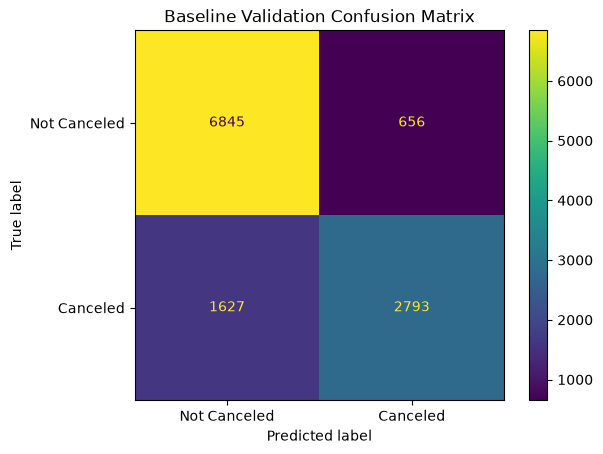

In [50]:
ConfusionMatrixDisplay(
    confusion_matrix=baseline_confusion_matrix,
    display_labels=[
        "Not Canceled",
        "Canceled"
    ]
).plot()

plt.title(
    "Baseline Validation Confusion Matrix"
)

plt.show()

In [51]:
baseline_val_precision = precision_score(
    y_val,
    baseline_val_predictions
)

baseline_val_recall = recall_score(
    y_val,
    baseline_val_predictions
)

baseline_val_f1 = f1_score(
    y_val,
    baseline_val_predictions
)

In [52]:
validation_metrics = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1"
    ],

    "Value": [
        baseline_val_precision,
        baseline_val_recall,
        baseline_val_f1
    ]
})

display(
    validation_metrics.round(4)
)

,Metric,Value
0,Precision,0.8098
1,Recall,0.6319
2,F1,0.7099


In [53]:
false_positives = baseline_confusion_matrix[0, 1]

false_negatives = baseline_confusion_matrix[1, 0]

print(
    "False positives:",
    false_positives
)

print(
    "False negatives:",
    false_negatives
)

False positives: 656
False negatives: 1627


In [54]:
if false_positives > false_negatives:
    more_common_error = "false positives"

elif false_negatives > false_positives:
    more_common_error = "false negatives"

else:
    more_common_error = "neither because the counts were equal"

print(
    "More common error:",
    more_common_error
)

More common error: false negatives


### Reflection 3.B — What the Baseline Misses

Based on your validation-set diagnostics:

1. Identify the **most important pattern or limitation** you observed in the baseline's predictions, citing at least one numerical result or plot.
2. Explain why this matters for the underlying prediction task.
3. Propose **one specific improvement or experiment** to investigate in Problems 4 or 5 that might address this limitation. Explain why you think it could help and what you expect to learn.

Write **a coherent response of approximately 100–150 words** in `a3b`.

In [55]:
# Your answer here, NOT in the next cell

a3b = """
The confusion matrix showed 656 false positives and 1627 false negatives, so false negatives were more common.
A false positive means the model predicted that a guest would cancel even though the booking was not canceled.
A false negative means the model expected the guest to keep the reservation, but the guest actually canceled.
False negatives can be a problem because the hotel may expect a room to be occupied and then lose that revenue when the guest cancels.
The validation precision was 0.8098, while the recall was 0.6319.
This difference shows that the overall F1 score does not explain every type of mistake the model makes.
For my first feature experiment, I would create a total-nights feature by combining weekday and weekend nights.
The full length of the stay may have a clearer relationship with cancellation than the two columns by themselves.
"""

In [56]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
The confusion matrix showed 656 false positives and 1627 false negatives, so false negatives were more common.
A false positive means the model predicted that a guest would cancel even though the booking was not canceled.
A false negative means the model expected the guest to keep the reservation, but the guest actually canceled.
False negatives can be a problem because the hotel may expect a room to be occupied and then lose that revenue when the guest cancels.
The validation precision was 0.8098, while the recall was 0.6319.
This difference shows that the overall F1 score does not explain every type of mistake the model makes.
For my first feature experiment, I would create a total-nights feature by combining weekday and weekend nights.
The full length of the stay may have a clearer relationship with cancellation than the two columns by themselves.



## Problem 4 — Feature Engineering Experiments [20 points]

In Problem 3, you established a baseline model using your original feature representation. In this problem, investigate whether changes to the predictor features improve validation performance.

Conduct **two distinct, hypothesis-driven feature-engineering experiments**. For each experiment, explain why the proposed change might help, implement it, and compare its results with the **unchanged baseline** from Problem 3.

- **Zillow:** Continue using `LinearRegression` and validation MAE (lower is better).
- **Hotel Booking:** Continue using `LogisticRegression` and validation F1 for cancellation class `1` (higher is better), with the default 0.5 classification threshold.

Keep the same training/validation partitions and baseline estimator settings. **Evaluate each change independently against the original baseline**, not cumulatively. Do not tune model hyperparameters or use the test set. Any transformations that learn parameters from the data must be fitted using training data only.

### Part A: Design and Evaluate Two Feature-Engineering Experiments [12 points]

Develop **two different feature-engineering changes** motivated by what you learned in Problems 1–3. Examples include a meaningful derived feature, a transformation of a skewed numerical predictor, or a different representation of an existing predictor. Choose changes appropriate to your dataset; do not simply remove predictors at random.

For each experiment:

1. State a specific **hypothesis**: what feature representation will you change, and why might it improve predictions?
2. Implement the change in a **reproducible, leakage-free workflow**. Apply the same feature definitions to training and validation data, fitting any learned transformations using training data only. Do not use validation performance to determine transformation parameters.
3. **Train a new model** using the same estimator type and hyperparameter settings as the original baseline, but with the modified feature representation. Generate training and validation predictions. Do not modify or overwrite `baseline_model`.
4. Report the **training and validation primary metric** for the experiment. Compare its validation score with the original baseline.

Present a compact results table with rows for **Baseline**, **Experiment 1**, and **Experiment 2**, including the feature change and both metric values. Keep code and plots necessary to understand the experiments visible in the notebook.

**Important:** Start each experiment from the original Problem 3 feature set and preprocessing design, making only that experiment's proposed change. Do not combine the two changes in this milestone.

**An experiment is not considered unsuccessful simply because validation performance fails to improve.** What matters is that you test a reasonable hypothesis, evaluate it correctly, and interpret the results.

In [57]:
# Your code here; add additional cells as needed.
# Implement and evaluate two independent feature-engineering experiments.
# Keep baseline_model unchanged and compare both experiments against it.

X_train_exp1 = X_train.copy()

X_val_exp1 = X_val.copy()

X_train_exp1["total_nights"] = (
    X_train_exp1["stays_in_week_nights"]
    + X_train_exp1["stays_in_weekend_nights"]
)

X_val_exp1["total_nights"] = (
    X_val_exp1["stays_in_week_nights"]
    + X_val_exp1["stays_in_weekend_nights"]
)

In [58]:
numerical_columns_exp1 = (
    numerical_columns
    + ["total_nights"]
)

In [59]:
preprocessor_exp1 = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_columns_exp1
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_columns
    )
])

In [60]:
experiment1_model = Pipeline([
    (
        "preprocessor",
        preprocessor_exp1
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

experiment1_model.fit(
    X_train_exp1,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['hotel','lead_time','arrival_date_year',...,'required_car_parking_spaces', 'total_of_special_requests','total_nights']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default 

In [61]:
experiment1_train_predictions = (
    experiment1_model.predict(
        X_train_exp1
    )
)

experiment1_val_predictions = (
    experiment1_model.predict(
        X_val_exp1
    )
)

In [62]:
experiment1_train_f1 = f1_score(
    y_train,
    experiment1_train_predictions
)

experiment1_val_f1 = f1_score(
    y_val,
    experiment1_val_predictions
)

In [63]:
X_train_exp2 = X_train.copy()

X_val_exp2 = X_val.copy()

X_train_exp2["log_lead_time"] = np.log1p(
    X_train_exp2["lead_time"]
)

X_val_exp2["log_lead_time"] = np.log1p(
    X_val_exp2["lead_time"]
)

In [64]:
numerical_columns_exp2 = (
    numerical_columns
    + ["log_lead_time"]
)

In [65]:
preprocessor_exp2 = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_columns_exp2
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_columns
    )
])

In [66]:
experiment2_model = Pipeline([
    (
        "preprocessor",
        preprocessor_exp2
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

experiment2_model.fit(
    X_train_exp2,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['hotel','lead_time','arrival_date_year',...,'required_car_parking_spaces', 'total_of_special_requests','log_lead_time']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default

In [67]:
experiment2_train_predictions = (
    experiment2_model.predict(
        X_train_exp2
    )
)

experiment2_val_predictions = (
    experiment2_model.predict(
        X_val_exp2
    )
)

In [68]:
experiment2_train_f1 = f1_score(
    y_train,
    experiment2_train_predictions
)

experiment2_val_f1 = f1_score(
    y_val,
    experiment2_val_predictions
)

In [69]:
feature_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Experiment 1",
        "Experiment 2"
    ],

    "Feature Change": [
        "Original features",
        "Added total nights",
        "Added log lead time"
    ],

    "Training F1": [
        baseline_train_f1,
        experiment1_train_f1,
        experiment2_train_f1
    ],

    "Validation F1": [
        baseline_val_f1,
        experiment1_val_f1,
        experiment2_val_f1
    ]
})

display(
    feature_results.round(4)
)

,Model,Feature Change,Training F1,Validation F1
0,Baseline,Original features,0.7174,0.7099
1,Experiment 1,Added total nights,0.7179,0.7104
2,Experiment 2,Added log lead time,0.7384,0.7383


### Reflection 4.A — Feature-Engineering Hypotheses and Results

For each of your two experiments:

1. Describe the feature change and **why you expected it to help**, connecting your hypothesis to characteristics of the dataset or the baseline's errors.
2. Report the **actual training and validation metric values** and quantify the change in validation performance relative to the original baseline.
3. Explain whether the result supports your hypothesis, what you learned from it, and identify one possible limitation of the experiment.

Write **a coherent response of approximately 150–200 words** in `a4a`.

In [70]:
# Your answer here, NOT in the next cell

a4a = """
For the first experiment, I created total_nights by combining weekday and weekend nights.
I thought the total length of a stay might have a clearer relationship with cancellations than keeping the nights separated.
The model had a training F1 of 0.7179 and a validation F1 of 0.7104.
This was only 0.0005 higher than the baseline validation score of 0.7099, so the change barely improved the model.
For the second experiment, I added the log of lead_time.
I tried this because lead time is skewed, and the difference between short lead times may matter more than the same size difference between very long lead times.
This model had a training F1 of 0.7384 and a validation F1 of 0.7383, which was 0.0284 higher than the baseline.
This result supported my second idea much more than my first one.
It showed that changing how an existing feature is represented can be more useful than simply combining two related columns.
One limitation is that I only tested each change with logistic regression, so they may work differently with other model types.
"""

In [71]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
For the first experiment, I created total_nights by combining weekday and weekend nights.
I thought the total length of a stay might have a clearer relationship with cancellations than keeping the nights separated.
The model had a training F1 of 0.7179 and a validation F1 of 0.7104.
This was only 0.0005 higher than the baseline validation score of 0.7099, so the change barely improved the model.
For the second experiment, I added the log of lead_time.
I tried this because lead time is skewed, and the difference between short lead times may matter more than the same size difference between very long lead times.
This model had a training F1 of 0.7384 and a validation F1 of 0.7383, which was 0.0284 higher than the baseline.
This result supported my second idea much more than my first one.
It showed that changing how an existing feature is represented can be more useful than simply combining two related columns.
One limitation is that I only tested each change with logistic regressi

### Part B: Compare the Experiments and Draw Conclusions [8 points]

Use your results from Part A to compare the two feature-engineering experiments and determine what they reveal about your selected prediction task.

1. **Compare all three feature representations**—the original baseline and both experiments. Identify which achieved the best validation performance and quantify its improvement or decline relative to the baseline.
2. Investigate **at least one difference beyond the primary validation metric**. For example, compare training–validation gaps, examine whether a particular error pattern improved, or investigate another relevant diagnostic measure. Support your analysis with a small table or plot.
3. Based on your findings, identify which feature changes, if any, you would consider carrying forward to the final project. Explain what additional experiments or evidence would help you decide.

**Do not combine the feature changes, tune hyperparameters, or evaluate on the test set.**

In [72]:
# Your code here; add additional cells as needed.
# Compare the baseline and both feature-engineering experiments.

baseline_precision = precision_score(
    y_val,
    baseline_val_predictions
)

experiment1_precision = precision_score(
    y_val,
    experiment1_val_predictions
)

experiment2_precision = precision_score(
    y_val,
    experiment2_val_predictions
)

In [73]:
baseline_recall = recall_score(
    y_val,
    baseline_val_predictions
)

experiment1_recall = recall_score(
    y_val,
    experiment1_val_predictions
)

experiment2_recall = recall_score(
    y_val,
    experiment2_val_predictions
)

In [74]:
diagnostic_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Experiment 1",
        "Experiment 2"
    ],

    "Validation F1": [
        baseline_val_f1,
        experiment1_val_f1,
        experiment2_val_f1
    ],

    "Validation Precision": [
        baseline_precision,
        experiment1_precision,
        experiment2_precision
    ],

    "Validation Recall": [
        baseline_recall,
        experiment1_recall,
        experiment2_recall
    ]
})

display(
    diagnostic_results.round(4)
)

,Model,Validation F1,Validation Precision,Validation Recall
0,Baseline,0.7099,0.8098,0.6319
1,Experiment 1,0.7104,0.8100,0.6326
2,Experiment 2,0.7383,0.8203,0.6713


### Reflection 4.B — What Did Feature Engineering Teach You?

1. Considering all three feature representations, what is your **overall conclusion** about the value of your feature-engineering experiments? Were the differences in validation performance large enough to be practically meaningful?
2. What did your additional diagnostic comparison reveal that the primary validation metric alone would not show?
3. Which feature changes, if any, would you consider carrying forward to the final project? Explain your reasoning and identify one important question that remains unanswered.

Support your conclusions with specific evidence from your results.

Write **a coherent response of approximately 100–150 words** in `a4b`.

In [75]:
# Your answer here, NOT in the next cell

a4b = """
Experiment 2 had the best validation F1 score at 0.7383, compared with 0.7104 for Experiment 1 and 0.7099 for the baseline.
The log lead-time feature improved the baseline by 0.0284, while total nights only improved it by 0.0005.
Looking beyond F1 showed that Experiment 2 increased precision from 0.8098 to 0.8203 and recall from 0.6319 to 0.6713.
This is useful because it shows that the model caught more actual cancellations without lowering the accuracy of its cancellation predictions.
The training and validation scores for Experiment 2 were also almost identical, so there was no obvious sign of overfitting from this result.
I would carry the log lead-time feature into the final project.
I would probably not keep total nights unless another model showed a clearer benefit.
One remaining question is whether log lead time would still help a random forest or neural network.
"""

In [76]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
Experiment 2 had the best validation F1 score at 0.7383, compared with 0.7104 for Experiment 1 and 0.7099 for the baseline.
The log lead-time feature improved the baseline by 0.0284, while total nights only improved it by 0.0005.
Looking beyond F1 showed that Experiment 2 increased precision from 0.8098 to 0.8203 and recall from 0.6319 to 0.6713.
This is useful because it shows that the model caught more actual cancellations without lowering the accuracy of its cancellation predictions.
The training and validation scores for Experiment 2 were also almost identical, so there was no obvious sign of overfitting from this result.
I would carry the log lead-time feature into the final project.
I would probably not keep total nights unless another model showed a clearer benefit.
One remaining question is whether log lead time would still help a random forest or neural network.



## Problem 5 — Compare Model Families [25 points]

In Problem 3, you established a linear or logistic regression baseline. In this problem, compare that baseline with a **tree ensemble** and a **feedforward neural network** to investigate how different model families perform on your selected prediction task.

Use the **original predictor representation from Problem 3**, not either feature-engineering experiment from Problem 4. Keep the same training/validation partitions and primary validation metric:

- **Zillow:** MAE (lower is better).
- **Hotel Booking:** F1 score for predicting canceled bookings (`is_canceled` = 1), with a classification threshold of 0.5.

Focus on a **fair initial comparison**, not an exhaustive search for the highest score. Fit all model parameters and learned preprocessing transformations using **training data only**. You may use validation data to evaluate and compare models, but **do not use the test set in this milestone**.

### Part A: Train and Compare Three Model Families [15 points]

Compare the fitted `baseline_model` from Problem 3 against **two new models**:

1. **Tree ensemble:** Train a `RandomForestRegressor` for Zillow or a `RandomForestClassifier` for Hotel Booking. Choose reasonable initial hyperparameter settings, including `random_state=42`. Do not perform a hyperparameter search.
2. **Feedforward neural network:** Build a modest Keras network with one or two hidden `Dense` layers and an appropriate output layer and loss function for your task. Set a random seed and use a fixed initial training configuration. Do not perform a hyperparameter search.
3. **Consistent evaluation:** Train both new models using the original Problem 3 predictor information and the same training partition. Fit all preprocessing transformations using training data only. You may adapt preprocessing to the needs of each model family (for example, numerical scaling or conversion to dense arrays), but **do not add or remove predictive features**.
4. **Compare results:** Report the training and validation primary metric for all three model families: the original baseline, the random forest, and the neural network. For Hotel Booking, use the same **0.5 classification threshold** for all models. Present the results in a compact, clearly labeled comparison table.

Retain the fitted models and preprocessing required to reproduce their predictions. You may include a neural-network learning curve if it helps explain the results.

**Choose initial model settings, train each new model once, and report the results without further tuning.** More systematic experimentation and optimization will take place in the final project. Do not use the modified feature representations from Problem 4 or evaluate on `X_test`.

In [77]:
# Your code here; add additional cells as needed.
# Compare baseline_model with a random forest and a feedforward neural network.
# Use the original Problem 3 features and the same train/validation split.
# Report training and validation metrics for all three models.
random_forest_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])


In [78]:
random_forest_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['hotel','lead_time','arrival_date_year',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

In [79]:
rf_train_predictions = random_forest_model.predict(
    X_train
)

rf_val_predictions = random_forest_model.predict(
    X_val
)

In [80]:
rf_train_f1 = f1_score(
    y_train,
    rf_train_predictions
)

rf_val_f1 = f1_score(
    y_val,
    rf_val_predictions
)

print("Random forest training F1:", rf_train_f1)

print("Random forest validation F1:", rf_val_f1)

Random forest training F1: 0.7313278184505104
Random forest validation F1: 0.7168724279835391


In [81]:
nn_preprocessor = baseline_model.named_steps[
    "preprocessor"
]

X_train_nn = nn_preprocessor.transform(
    X_train
)

X_val_nn = nn_preprocessor.transform(
    X_val
)

In [82]:
if hasattr(X_train_nn, "toarray"):
    X_train_nn = X_train_nn.toarray()

if hasattr(X_val_nn, "toarray"):
    X_val_nn = X_val_nn.toarray()

X_train_nn = X_train_nn.astype("float32")

X_val_nn = X_val_nn.astype("float32")

In [83]:
print("Neural network training shape:", X_train_nn.shape)

print("Neural network validation shape:", X_val_nn.shape)

Neural network training shape: (95367, 154)
Neural network validation shape: (11921, 154)


In [84]:
tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(42)

In [85]:
neural_network_model = Sequential([
    Input(shape=(X_train_nn.shape[1],)),

    Dense(
        64,
        activation="relu"
    ),

    Dense(
        32,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

In [86]:
neural_network_model.compile(
    optimizer=Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]
)

In [87]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [88]:
neural_network_history = neural_network_model.fit(
    X_train_nn,
    y_train,

    validation_data=(
        X_val_nn,
        y_val
    ),

    epochs=50,
    batch_size=64,

    callbacks=[
        early_stopping
    ],

    verbose=0
)

print(
    "Epochs trained:",
    len(neural_network_history.history["loss"])
)

Epochs trained: 14


In [89]:
nn_train_probabilities = neural_network_model.predict(
    X_train_nn,
    verbose=0
).ravel()

nn_val_probabilities = neural_network_model.predict(
    X_val_nn,
    verbose=0
).ravel()

In [90]:
nn_train_predictions = (
    nn_train_probabilities >= 0.50
).astype(int)

nn_val_predictions = (
    nn_val_probabilities >= 0.50
).astype(int)

In [91]:
nn_train_f1 = f1_score(
    y_train,
    nn_train_predictions
)

nn_val_f1 = f1_score(
    y_val,
    nn_val_predictions
)

print("Neural network training F1:", nn_train_f1)

print("Neural network validation F1:", nn_val_f1)

Neural network training F1: 0.8256875305117091
Neural network validation F1: 0.8021899547726732


In [92]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Neural Network"
    ],

    "Training F1": [
        baseline_train_f1,
        rf_train_f1,
        nn_train_f1
    ],

    "Validation F1": [
        baseline_val_f1,
        rf_val_f1,
        nn_val_f1
    ]
})

display(
    model_comparison.round(4)
)

,Model,Training F1,Validation F1
0,Logistic Regression,0.7174,0.7099
1,Random Forest,0.7313,0.7169
2,Neural Network,0.8257,0.8022


### Reflection 5.A — Comparing Model Families

1. Compare the training and validation results for all three model families, citing **specific metric values** from your results table. Which model performed best on the validation set, and by how much relative to the baseline?
2. What evidence, if any, suggests underfitting or overfitting? Explain why **better training performance does not necessarily mean better generalization**.
3. Discuss one practical tradeoff among the model families, such as interpretability, training complexity, or sensitivity to preprocessing.

Base your discussion on your own results. Write **a coherent response of approximately 150–200 words** in `a5a`.

In [93]:
# Your answer here, NOT in the next cell

a5a = """
The neural network performed the best out of the three models.
Logistic regression had a training F1 of 0.7174 and a validation F1 of 0.7099.
The random forest improved slightly, with a training F1 of 0.7313 and a validation F1 of 0.7169.
The neural network had a training F1 of 0.8257 and a validation F1 of 0.8022, which was 0.0923 higher than the logistic regression baseline.
All three models scored higher on the training data than the validation data.
The neural network had the largest gap, so there may be some overfitting, although its validation performance was still the strongest.
A high training score alone would not make a model better because the main goal is to perform well on data it did not train on.
Logistic regression is easier to explain and faster to train, while the neural network takes more time and preprocessing.
Based on these results, the extra complexity of the neural network seems useful because it produced a noticeable improvement on the validation set.
"""

In [94]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5a = {a5a}")

a5a = 
The neural network performed the best out of the three models.
Logistic regression had a training F1 of 0.7174 and a validation F1 of 0.7099.
The random forest improved slightly, with a training F1 of 0.7313 and a validation F1 of 0.7169.
The neural network had a training F1 of 0.8257 and a validation F1 of 0.8022, which was 0.0923 higher than the logistic regression baseline.
All three models scored higher on the training data than the validation data.
The neural network had the largest gap, so there may be some overfitting, although its validation performance was still the strongest.
A high training score alone would not make a model better because the main goal is to perform well on data it did not train on.
Logistic regression is easier to explain and faster to train, while the neural network takes more time and preprocessing.
Based on these results, the extra complexity of the neural network seems useful because it produced a noticeable improvement on the validation set.



### Part B: Investigate Model Complexity and Draw Conclusions [10 points]

Choose **one** of the two new model families (random forest or neural network) and conduct **one controlled experiment** to investigate model complexity.

1. State a hypothesis about how **one complexity-related setting** might influence training and validation performance. Examples include `max_depth` for the random forest or the number of units in a neural-network hidden layer.
2. Starting with the model configuration used in Part A, train **one additional version** of the selected model, changing **only the chosen complexity setting**. Keep the same features, data partitions, evaluation metric, and other model settings. Fit preprocessing transformations using training data only, and use `random_state=42` or the same Keras seed where applicable.
3. Compare the **original and modified versions** using both training and validation performance. Display a compact table or plot showing the effect of the change.
4. Based on all your results from Problem 5, identify which model family appears most promising for further investigation in the **final project**. Explain your choice and propose one additional experiment or question worth pursuing during the final three weeks.

Your goal is to understand the **effect of a controlled change**, not necessarily to improve performance. **Do not perform grid search, evaluate on the test set, or claim that a single validation result establishes which model will generalize best.**

In [95]:
# Your code here; add additional cells as needed.
# Change one complexity-related setting in either the random forest or neural network.
# Compare its training and validation performance with the original version.
simpler_forest_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=6,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [96]:
simpler_forest_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['hotel','lead_time','arrival_date_year',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

In [97]:
simpler_rf_train_predictions = (
    simpler_forest_model.predict(
        X_train
    )
)

simpler_rf_val_predictions = (
    simpler_forest_model.predict(
        X_val
    )
)

In [98]:
simpler_rf_train_f1 = f1_score(
    y_train,
    simpler_rf_train_predictions
)

simpler_rf_val_f1 = f1_score(
    y_val,
    simpler_rf_val_predictions
)

In [99]:
forest_complexity_results = pd.DataFrame({
    "Random Forest": [
        "Original: depth 12",
        "Simpler: depth 6"
    ],

    "Training F1": [
        rf_train_f1,
        simpler_rf_train_f1
    ],

    "Validation F1": [
        rf_val_f1,
        simpler_rf_val_f1
    ]
})

display(
    forest_complexity_results.round(4)
)

,Random Forest,Training F1,Validation F1
0,Original: depth 12,0.7313,0.7169
1,Simpler: depth 6,0.5460,0.5318


### Reflection 5.B — Complexity and Next Steps

1. What complexity setting did you change, and why did you expect it to affect model behavior?
2. Report the **actual training and validation results** before and after the change. What do these results suggest about the relationship between model complexity, overfitting or underfitting, and generalization?
3. Based on the model-family comparisons and this experiment, which approach would you investigate further in the final project? Explain your choice and identify one important uncertainty that remains.

Support your conclusions with specific results. Write **a coherent response of approximately 125–175 words** in `a5b`.

In [100]:
# Your answer here, NOT in the next cell

a5b = """
For the complexity experiment, I changed the random forest maximum depth from 12 to 6.
I expected the smaller depth to reduce overfitting, but I also knew that making the trees too shallow could prevent the model from learning enough patterns.
The original forest had a training F1 of 0.7313 and a validation F1 of 0.7169.
The simpler forest dropped to a training F1 of 0.5460 and a validation F1 of 0.5318.
Since both scores decreased by a large amount, the depth-six model appears to underfit the data.
The original model had a small training-validation gap, so reducing its complexity did not help.
For the final project, I would focus more on the neural network because it had the best validation F1 at 0.8022.
I would test whether using the log lead-time feature with the neural network improves it further.
One uncertainty is whether that improvement would remain after changing the network size, regularization, or training settings.
"""

In [101]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a5b = {a5b}")

a5b = 
For the complexity experiment, I changed the random forest maximum depth from 12 to 6.
I expected the smaller depth to reduce overfitting, but I also knew that making the trees too shallow could prevent the model from learning enough patterns.
The original forest had a training F1 of 0.7313 and a validation F1 of 0.7169.
The simpler forest dropped to a training F1 of 0.5460 and a validation F1 of 0.5318.
Since both scores decreased by a large amount, the depth-six model appears to underfit the data.
The original model had a small training-validation gap, so reducing its complexity did not help.
For the final project, I would focus more on the neural network because it had the best validation F1 at 0.8022.
I would test whether using the log lead-time feature with the neural network improves it further.
One uncertainty is whether that improvement would remain after changing the network size, regularization, or training settings.



## Submission Checklist

Before submitting your milestone notebook to Gradescope, verify the following:

-  **All five problems are complete**, including the required code, tables, plots, and reflections.
-  You explored both datasets in Problem 1 and used your selected dataset consistently throughout Problems 2–5.
-  Your training, validation, and test partitions are correctly defined, and all learned preprocessing transformations were fitted using training data only.
-  You evaluated the baseline, feature-engineering experiments, and three model families using the required validation metric.
-  **You did not evaluate any model on the test set.** The test set is reserved for the final project.
-  All reflection variables (`a1a`, `a1b`, `a2a`–`a2d`, `a3a`, `a3b`, `a4a`, `a4b`, `a5a`, `a5b`) contain your own substantive answers.
-  You ran all the **Graded Answer** cells without modifying them.
-  You restarted the kernel and ran the entire notebook from beginning to end without errors.
-  All relevant code output, tables, and plots are visible in the submitted notebook.

**Submit your completed `.ipynb` file to Gradescope.** Do not submit the datasets or any additional files.

**Due: Sunday, November 15th at 11:59 PM**, with a 2-hour and 1-minute grace period. 

**No late submissions -- We have to start grading immediately!**